# Evaluate a training run
Select a completed `3_train` output folder, then run the cells in order. The notebook shows saved history and metrics, reloads the adapter, and scores the saved validation and test pairs. Test labels are used for reporting only; the decision threshold is the one selected on validation during training.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from peft import PeftModel
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer


/home/petrecc1/miniforge3/envs/SciARvenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration
Paths may be absolute or relative to the repository root. Set `DATA_PATH` if the dataset has moved. Use the original dataset version; the saved configuration only records its location, not a content hash.

In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / '3_train').is_dir():
    ROOT = ROOT.parent
if not (ROOT / '3_train').is_dir():
    raise FileNotFoundError('Start Jupyter from the repository root or 4_evaluation directory.')
RUN_DIR = ROOT / '3_train/outputs/SciAR_100k'  # Change to your completed run
DATA_PATH = None  # e.g. ROOT / 'data/processed/sciar_refereed_v0/papers.parquet'

RUN_DIR = Path(RUN_DIR).expanduser()
if not RUN_DIR.is_absolute():
    RUN_DIR = ROOT / RUN_DIR
config = json.loads((RUN_DIR / 'config.json').read_text())
metrics = json.loads((RUN_DIR / 'metrics.json').read_text())
history = pd.read_csv(RUN_DIR / 'history.csv')
data_path = Path(DATA_PATH if DATA_PATH is not None else config['DATA_PATH']).expanduser()
if not data_path.is_absolute():
    data_path = ROOT / data_path
if not data_path.is_file():
    raise FileNotFoundError(f'Dataset not found: {data_path}. Set DATA_PATH above.')
threshold = float(metrics['threshold'])
print(f'Run: {RUN_DIR}\nDataset: {data_path}\nSaved validation threshold: {threshold:.6f}')


Run: /home/petrecc1/projects/SciAR/3_train/outputs/SciAR_100k
Dataset: /home/petrecc1/projects/SciAR/data/processed/sciar_refereed_v1/papers.parquet
Saved validation threshold: 0.420032


## Saved results and training history

,value
baseline_val_auc,0.648756
best_epoch,5.000000
baseline_test_auc,0.635228
val_auc,0.727306
val_accuracy,0.668500
threshold,0.420032
test_loss,0.288112
test_auc,0.737827
test_accuracy,0.670600


,value
ROOT,/home/petrecc1/projects/SciAR
DATA_PATH,/home/petrecc1/projects/SciAR/data/processed/s...
READER_PATH,/home/petrecc1/projects/SciAR/2_Data/data_read...
OUTPUT_DIR,/home/petrecc1/projects/SciAR/3_train/outputs/...
PAIR_READER,specter
SPECTER_MODEL,allenai/specter
SPECTER_CACHE_DIR,/home/petrecc1/projects/SciAR/data/cache/specter
SPECTER_PRECISION,float16
SPECTER_BATCH_SIZE,32
SPECTER_MATCH_BATCH_SIZE,16


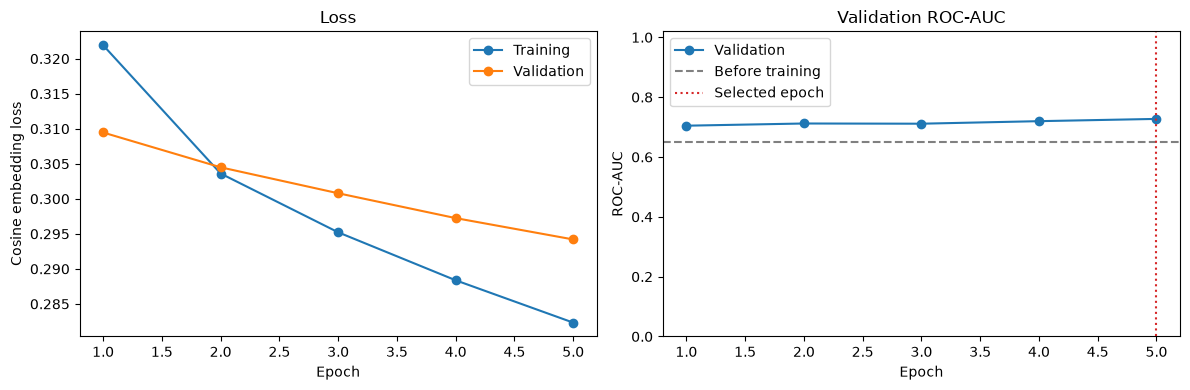

In [3]:
display(pd.Series(metrics, name='value').to_frame())
display(pd.Series(config, name='value').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['epoch'], history['train_loss'], marker='o', label='Training')
axes[0].plot(history['epoch'], history['val_loss'], marker='o', label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cosine embedding loss', title='Loss')
axes[0].legend()
axes[1].plot(history['epoch'], history['val_auc'], marker='o', label='Validation')
axes[1].axhline(metrics['baseline_val_auc'], color='gray', linestyle='--', label='Before training')
axes[1].axvline(metrics['best_epoch'], color='tab:red', linestyle=':', label='Selected epoch')
axes[1].set(xlabel='Epoch', ylabel='ROC-AUC', ylim=(0, 1.02), title='Validation ROC-AUC')
axes[1].legend()
fig.tight_layout()
plt.show()


## Load pairs and paper text
Pairs are sampled with replacement; repeated pairs remain in the evaluation. Each text is the title, two newlines, and the abstract, as in training.

In [4]:
pair_sets = {name: pd.read_csv(RUN_DIR / f'{name}_pairs.csv') for name in ('validation', 'test')}
for name, pairs in pair_sets.items():
    if pairs.empty or not {'bibcode_a', 'bibcode_b', 'label'}.issubset(pairs.columns):
        raise ValueError(f'{name} pairs are empty or missing required columns')
    if not pairs['label'].isin([0, 1]).all():
        raise ValueError(f'{name} labels must be 0 or 1')
    print(f"{name}: {len(pairs):,} pairs; label counts: {pairs['label'].value_counts().sort_index().to_dict()}")
needed = set().union(*(set(p['bibcode_a']) | set(p['bibcode_b']) for p in pair_sets.values()))
papers = pd.read_parquet(data_path, columns=['bibcode', 'title', 'abstract'])
papers = papers[papers['bibcode'].isin(needed)]
if papers['bibcode'].duplicated().any():
    raise ValueError('Dataset contains duplicate bibcodes among evaluation papers')
missing = needed - set(papers['bibcode'])
if missing:
    raise ValueError(f'{len(missing)} pair bibcodes missing from dataset; check DATA_PATH. Examples: {sorted(missing)[:5]}')
if papers[['title', 'abstract']].isna().any().any():
    raise ValueError('Evaluation papers contain missing title or abstract text')
texts = (papers.set_index('bibcode')['title'] + '\n\n' + papers.set_index('bibcode')['abstract']).to_dict()


validation: 2,000 pairs; label counts: {0: 1000, 1: 1000}
test: 5,000 pairs; label counts: {0: 2500, 1: 2500}


## Reload adapter and score pairs
The original base checkpoint may need to be downloaded. CUDA runs use mixed precision only if the saved run did; CPU runs use full precision. Different hardware or precision can cause small differences from the saved metrics, particularly near the threshold.

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = bool(config.get('USE_AMP', False) and device.type == 'cuda')
batch_size = int(config['BATCH_SIZE'])
tokenizer = AutoTokenizer.from_pretrained(RUN_DIR / 'adapter')
base = AutoModel.from_pretrained(config['MODEL_NAME'], add_pooling_layer=False)
model = PeftModel.from_pretrained(base, RUN_DIR / 'adapter').to(device).eval()
print(f'Device: {device}, mixed precision: {use_amp}')


@torch.no_grad()
def score_pairs(pairs):
    scores = []
    for start in tqdm(range(0, len(pairs), batch_size), desc='Scoring'):
        batch = pairs.iloc[start:start + batch_size]
        batch_texts = [texts[b] for b in batch['bibcode_a']] + [texts[b] for b in batch['bibcode_b']]
        tokens = tokenizer(batch_texts, padding=True, truncation=True, max_length=int(config['MAX_LENGTH']), return_tensors='pt')
        tokens = {key: value.to(device) for key, value in tokens.items()}
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            hidden = model(**tokens).last_hidden_state
            mask = tokens['attention_mask'].unsqueeze(-1).to(hidden.dtype)
            embeddings = F.normalize((hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1), p=2, dim=-1)
            left, right = embeddings.chunk(2)
        scores.extend((left.float() * right.float()).sum(dim=-1).cpu().tolist())
    return np.asarray(scores)


scores = {name: score_pairs(pairs) for name, pairs in pair_sets.items()}


Device: cuda, mixed precision: True


Scoring: 100%|██████████| 1250/1250 [00:42<00:00, 29.59it/s]


## Evaluation metrics
ROC-AUC measures ranking across thresholds. Accuracy and balanced accuracy use the saved validation-selected threshold; scores greater than or equal to it predict the same author. The saved and recomputed values may differ slightly across devices.

In [6]:
rows = []
for name, pairs in pair_sets.items():
    labels = pairs['label'].to_numpy()
    predictions = scores[name] >= threshold
    auc = roc_auc_score(labels, scores[name]) if len(np.unique(labels)) == 2 else np.nan
    prefix = 'val' if name == 'validation' else 'test'
    rows.append({'split': name, 'pairs': len(labels), 'ROC-AUC': auc, 'saved ROC-AUC': metrics.get(f'{prefix}_auc'), 'accuracy': accuracy_score(labels, predictions), 'saved accuracy': metrics.get(f'{prefix}_accuracy'), 'balanced accuracy': balanced_accuracy_score(labels, predictions)})
display(pd.DataFrame(rows).set_index('split'))


,pairs,ROC-AUC,saved ROC-AUC,accuracy,saved accuracy,balanced accuracy
split,,,,,,
validation,2000,0.727306,0.727306,0.6685,0.6685,0.6685
test,5000,0.737827,0.737827,0.6706,0.6706,0.6706


## SPECTER baseline on the same pairs
The saved pairs record the SPECTER similarity used during sampling. Ranking pairs by that score alone shows how a pure topic-similarity model performs on the same authorship labels, with no retraining or reload. Compare it with the fine-tuned AUCs above.

In [7]:
rows = []
for name, pairs in pair_sets.items():
    if 'specter_similarity' not in pairs.columns:
        raise ValueError(f'{name}_pairs.csv has no specter_similarity column; expected SPECTER-mode pairs')
    rows.append({'split': name, 'pairs': len(pairs),
                 'SPECTER ROC-AUC': roc_auc_score(pairs['label'], pairs['specter_similarity'])})
display(pd.DataFrame(rows).set_index('split'))

,pairs,SPECTER ROC-AUC
split,,
validation,2000,0.536681
test,5000,0.532148


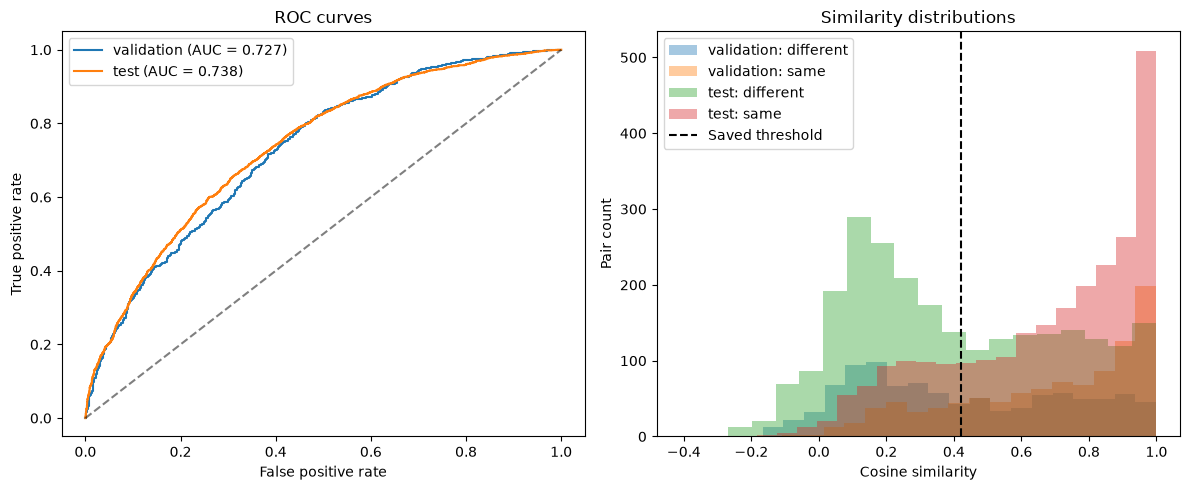

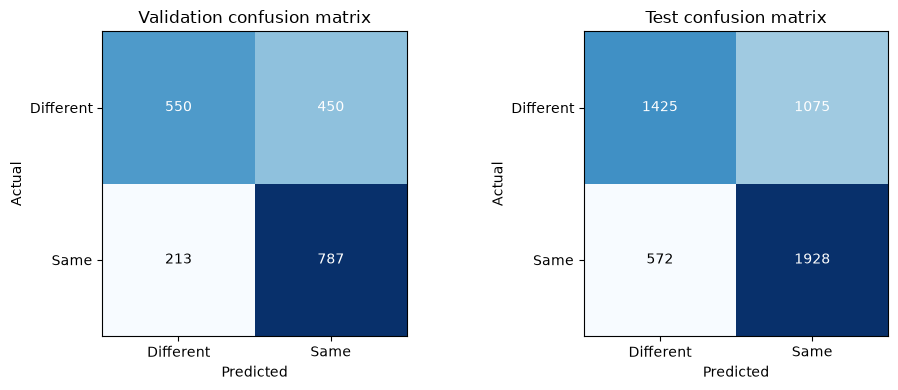

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, pairs in pair_sets.items():
    labels = pairs['label'].to_numpy()
    if len(np.unique(labels)) == 2:
        fpr, tpr, _ = roc_curve(labels, scores[name])
        axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(labels, scores[name]):.3f})')
    for label, description in [(0, 'different'), (1, 'same')]:
        axes[1].hist(scores[name][labels == label], bins=20, alpha=0.4, label=f'{name}: {description}')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
axes[0].legend()
axes[1].axvline(threshold, color='black', linestyle='--', label='Saved threshold')
axes[1].set(xlabel='Cosine similarity', ylabel='Pair count', title='Similarity distributions')
axes[1].legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pairs) in zip(axes, pair_sets.items()):
    matrix = confusion_matrix(pairs['label'], scores[name] >= threshold, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for (i, j), count in np.ndenumerate(matrix):
        ax.text(j, i, str(count), ha='center', va='center', color='white' if count > matrix.max() / 2 else 'black')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Different', 'Same'], yticklabels=['Different', 'Same'], xlabel='Predicted', ylabel='Actual', title=f'{name.title()} confusion matrix')
fig.tight_layout()
plt.show()


These pairs measure author similarity on the sampled data. Topic overlap can influence scores, and first-author identity is a proxy rather than proof of authorship.